In [24]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from datetime import date
import re
from tqdm import tqdm
import time
from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr
from scipy.spatial.distance import jaccard, euclidean
import functools
import operator

today = date.today()

# Get Distributions to find percentiles

This notebook was used to test individual data modalities to see how to score equally across different types of data. This notebook's method was to find the distribution of all the data types and use percentiles as a universal scoring method.

This method is then used in the other notebooks to combine scores.

**STRING Associations**

In [16]:
protein_assoc_sub = pd.read_pickle('../data/hg19-protein-associations.pkl')
protein_assoc_sub

,protein2,neighborhood,neighborhood_transferred,fusion,cooccurence,homology,coexpression,coexpression_transferred,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,,,,,,,
9606.ENSP00000000233,9606.ENSP00000379496,0,0,0,0,0,0,54,0,0,0,0,103,85,155,ARF5,PDE1C
9606.ENSP00000000233,9606.ENSP00000314067,0,0,0,0,0,0,0,0,180,0,0,0,61,197,ARF5,PAK2
9606.ENSP00000000233,9606.ENSP00000263116,0,0,0,0,0,0,62,0,152,0,0,0,101,222,ARF5,RAB36
9606.ENSP00000000233,9606.ENSP00000361263,0,0,0,0,0,0,0,0,161,0,0,47,58,181,ARF5,RAPGEF1
9606.ENSP00000000233,9606.ENSP00000409666,0,0,0,0,0,60,63,0,213,0,0,0,72,270,ARF5,SUMO3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000485678,9606.ENSP00000321447,0,0,0,0,888,214,49,0,0,0,0,0,0,220,OR6Q1,OR4S1
9606.ENSP00000485678,9606.ENSP00000308270,0,0,0,0,899,152,0,0,0,0,0,0,0,151,OR6Q1,OR5B3
9606.ENSP00000485678,9606.ENSP00000335660,0,0,0,0,0,182,0,0,0,0,0,0,0,181,OR6Q1,KRTAP19-2


In [17]:
protein_list = list(set(protein_assoc_sub.protein1_pref.tolist()+protein_assoc_sub.protein2_pref.tolist()))
print(len(protein_list))

18071


In [18]:
numzeros = np.zeros(18071**2 - len(protein_assoc_sub))
zerodistr = np.append(numzeros, protein_assoc_sub.combined_score.to_numpy(), axis=0)
distr = protein_assoc_sub.combined_score.to_numpy()

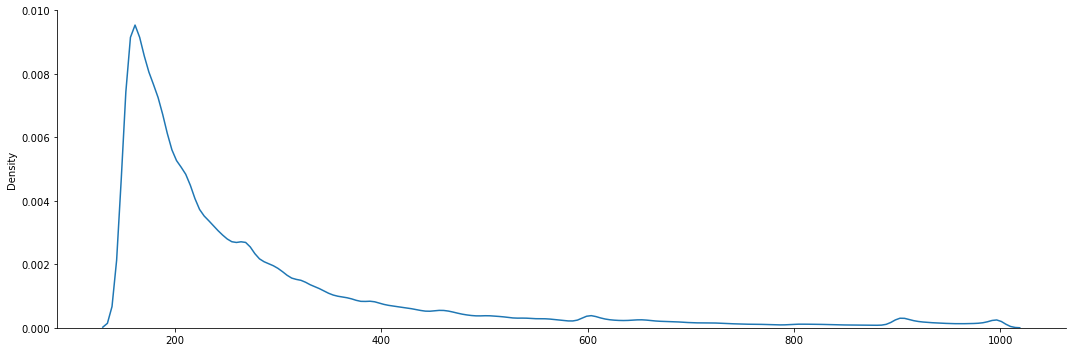

In [20]:
sns.displot(distr, kind = 'kde', height=5, aspect=3)

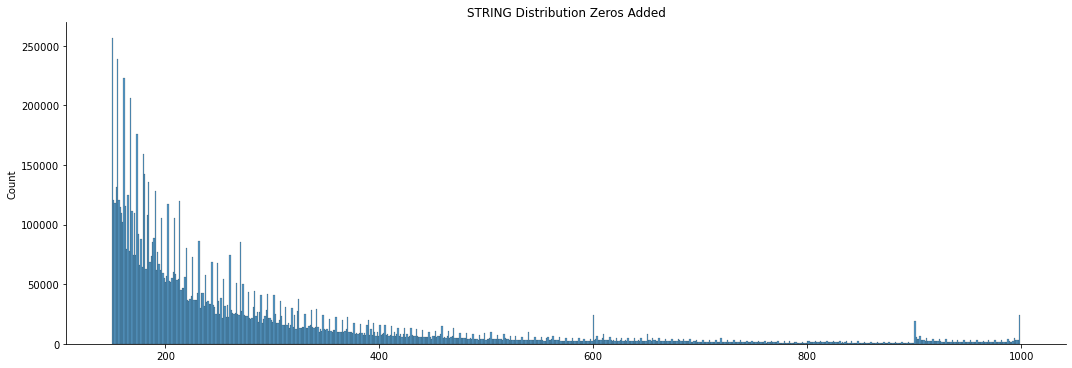

In [21]:
distr_plot = sns.displot(distr, height=5, aspect=3)
distr_plot.set(title='STRING Distribution Zeros Added')

In [22]:
percentileofscore(zerodistr, 150)

96.67423876812053

In [23]:
percentileofscore(distr, 750)

96.4729943720952

In [103]:
gata1 = pd.read_pickle('../data/GATA1_top-STRING-associations.pkl')
gata1[['protein1_pref', 'protein2_pref']].to_pickle('../data/GATA1-STRING-associated-protein-names.pkl')
# gata1['combined_score'][:100]

In [25]:
percentileofscore(zerodistr, 643)

99.81807428767965

**DHS distribution**

In [9]:
dhs_df = pd.read_pickle('../data/data_240.pkl')
dhs_df
dhs_metadata_df = pd.read_pickle('../data/dhs_metadata.pkl')

,DS10018,DS10060,DS10518,DS10666,DS11872,DS11909,DS11939,DS12274,DS12352,DS12357,...,DS55945A,DS55923A,DS39148B,DS39417A,DS23388A,DS24714A,DS24801A,DS24814A,DS36206B,DS37716C
identifier,,,,,,,,,,,,,,,,,,,,,
1.10011,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.10021,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.10025,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.10027,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.1003,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y.994281,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Y.994286,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Y.994292,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [10]:
# file = open('../output/dhs-jaccard-240s-scores-every-100.pkl','r')
with open('../output/dhs-jaccard-240s-scores-every-100.pkl', "rb") as input_file:
    dhs_scores = pickle.load(input_file)
dhs_scores_list = list(itertools.chain.from_iterable(dhs_scores))

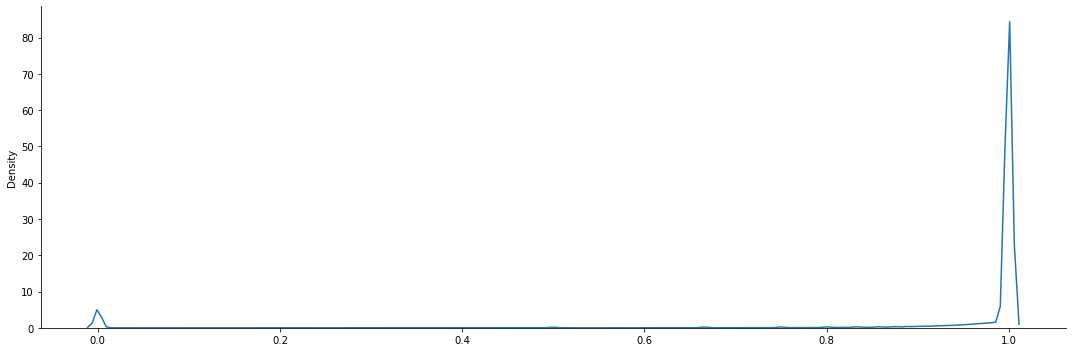

In [12]:
sns.displot(dhs_scores_list, kind='kde', height=5, aspect=3)

In [28]:
dhs_df = pd.read_pickle('../data/data_240.pkl')

dhs_arr = dhs_df.to_numpy()

dhs_arr[1]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [26]:
hg38_dhs_ranges = dict()

hg38_chromosomes = {
    'chr1': 248956422,
    'chr2': 242193529,
    'chr3': 198295559,
    'chr4': 190214555,
    'chr5': 181538259,
    'chr6': 170805979,
    'chr7': 159345973,
    'chr8': 145138636,
    'chr9': 138394717,
    'chr10': 133797422,
    'chr11': 135086622,
    'chr12': 133275309,
    'chr13': 114364328,
    'chr14': 107043718,
    'chr15': 101991189,
    'chr16': 90338345,
    'chr17': 83257441,
    'chr18': 80373285,
    'chr19': 58617616,
    'chr20': 64444167,
    'chr21': 46709983,
    'chr22': 50818468,
    'chrX': 156040895,
    'chrY': 57227415
}

In [ ]:
similar_dhs_indices = np.where(dhs_scores[-1] == 0)[0]
print(similar_dhs_indices)

In [ ]:
dhs_sub = dhs_metadata_df.iloc[similar_dhs_indices*100, :]

In [8]:
percentileofscore(dhs_scores_list, 0)

2.455230311596232

In [9]:
percentileofscore(dhs_scores_list, 0.69)

5.519243179137332

# Get Combined Score

In [37]:
def process_bedfile(assembly):
    ## READ IN BED FILE WITH COORDINATES
    
    if assembly == 'hg19':
        gene_df = pd.read_csv('../data/hg19.gencode.v19.annotation.hgnc.longest.gtf.bed14',
                      delimiter='\t', header = None, index_col=3)
    elif assembly == 'hg38':
        gene_df = pd.read_csv('../data/hg38.gencode.v38.annotation.gtf.genePred.hgnc.longest.noChrM.bed',
                      delimiter='\t', header = None, index_col=3)
    
    genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-' + assembly + '.pkl')
    
    gene_df = gene_df.rename({3:'gene_names', 0:'chr', 1:'start', 2:'end', 5:'strand', 9:'descriptor'}, axis=1)
    gene_df.index = gene_df.index.rename('gene_names')
    
    # Remove duplicate genes
    gene_df_no_dupes = gene_df[~gene_df.index.duplicated(keep='first')]
    print(gene_df_no_dupes.shape, gene_df.shape)

    # Remove duplicate genes from 'genes_in_both'
    genes_in_both_df = gene_df_no_dupes.loc[genes_in_both.preferred_name.tolist()].reset_index()
    genes_in_both_dup_removed = genes_in_both_df.drop_duplicates(subset=['gene_names'])
    print(genes_in_both_df.shape, genes_in_both_dup_removed.shape)
    genes_in_both_dup_removed.set_index('gene_names', inplace=True)
    return genes_in_both_dup_removed

In [29]:
protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
protein_assoc_sub

,protein2,neighborhood,neighborhood_transferred,fusion,cooccurence,homology,coexpression,coexpression_transferred,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,,,,,,,
9606.ENSP00000000233,9606.ENSP00000379496,0,0,0,0,0,0,54,0,0,0,0,103,85,155,ARF5,PDE1C
9606.ENSP00000000233,9606.ENSP00000314067,0,0,0,0,0,0,0,0,180,0,0,0,61,197,ARF5,PAK2
9606.ENSP00000000233,9606.ENSP00000263116,0,0,0,0,0,0,62,0,152,0,0,0,101,222,ARF5,RAB36
9606.ENSP00000000233,9606.ENSP00000361263,0,0,0,0,0,0,0,0,161,0,0,47,58,181,ARF5,RAPGEF1
9606.ENSP00000000233,9606.ENSP00000409666,0,0,0,0,0,60,63,0,213,0,0,0,72,270,ARF5,SUMO3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000485678,9606.ENSP00000354800,0,0,0,0,872,213,0,0,0,0,0,0,0,213,OR6Q1,OR5D13
9606.ENSP00000485678,9606.ENSP00000308270,0,0,0,0,899,152,0,0,0,0,0,0,0,151,OR6Q1,OR5B3
9606.ENSP00000485678,9606.ENSP00000335660,0,0,0,0,0,182,0,0,0,0,0,0,0,181,OR6Q1,KRTAP19-2


In [30]:
hg38_proc_gene_df = process_bedfile('hg38')
hg38_proc_gene_df.iloc[:5, :]

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


,chr,start,end,4,strand,6,7,8,descriptor,10,11,12,13
gene_names,,,,,,,,,,,,,
ARF5,chr7,127588385,127591681,8,+,ENST00000463733,658,protein-coding,ADP ribosylation factor 5,127591681,127591681,"127588385,127589082,127589484,127590962,127591...","127588565,127589163,127590137,127591088,127591..."
M6PR,chr12,8940363,8949761,21,-,ENST00000536844,6752,protein-coding,"mannose-6-phosphate receptor, cation dependent",8941817,8946404,"8940363,8943800,8945417,8946228,8949487,","8941940,8943910,8945584,8946405,8949761,"
FKBP4,chr12,2794969,2805423,53,+,ENST00000001008,3720,protein-coding,FKBP prolyl isomerase 4,2795139,2803258,"2794969,2797137,2797728,2798705,2799087,279984...","2795244,2797282,2797871,2798826,2799244,279994..."
CYP26B1,chr2,72129237,72147862,29,-,ENST00000001146,20581,protein-coding,cytochrome P450 family 26 subfamily B member 1,72132226,72147834,"72129237,72133022,72134760,72135143,72143988,7...","72132619,72133307,72134916,72135419,72144213,7..."
NDUFAF7,chr2,37231657,37249160,5,+,ENST00000002125,28816,protein-coding,NADH:ubiquinone oxidoreductase complex assembl...,37231705,37248350,"37231657,37232105,37236095,37237756,37241577,3...","37231760,37232266,37236176,37237867,37241791,3..."


In [31]:


GATA1_bed_info = hg38_proc_gene_df[hg38_proc_gene_df.index == 'GATA1']
GATA1_bed_info

,chr,start,end,4,strand,6,7,8,descriptor,10,11,12,13
gene_names,,,,,,,,,,,,,
GATA1,chrX,48786572,48794311,233,+,ENST00000376665,4170,protein-coding,GATA binding protein 1,48791109,48794268,"48786572,48791090,48791843,48792322,48793171,4...","48786645,48791329,48792221,48792468,48793297,4..."


In [32]:
## Upstream of GATA1
GATA1_up_coord_1 = 'chrX 48786500'
GATA1_up_coord_2 = 'chrX 48782500'

In [25]:
# Go through each category to find closest object

# STRING
hg38_gene_ranges_fn = open('../data/hg38_gene_ranges.pkl', "rb")
hg38_gene_ranges = pickle.load(hg38_gene_ranges_fn)

# def findWithinRegion_gene(start, stop):
    

def findNearestGene(coord, gene_ranges):    
    # Subset genes_df to just same chromosome
    coord = coord.split(' ')
    chrm = coord[0]
    coord = int(coord[1])
    
    chrm_range = gene_ranges[chrm]
    chrm_range_list = list(chrm_range)
    
    for i, interval in enumerate(chrm_range_list):
        if coord in range(interval[0], interval[1]):
            return chrm_range[interval]
        
# DHS
def findNearestDHS(coord):
    coord = coord.split(' ')
    chrm = coord[0]
    coord = int(coord[1])
    
    dhs_metadata_df = pd.read_pickle('../data/dhs_metadata.pkl')
    dhs_metadata_sub = dhs_metadata_df[dhs_metadata_df['seqname'] == chrm]

    return dhs_metadata_sub.loc[(dhs_metadata_sub['start'] < coord) & (dhs_metadata_sub['end'] > coord)]

def getDHSRecommendations(closest_dhs):
    dhs_df = pd.read_pickle('../data/data_240.pkl')

    dhs_arr = dhs_df.to_numpy()
    
    closest_dhs_index = dhs_df.index.tolist().index(closest_dhs)

    dist = []

    for i, row in enumerate(dhs_df.index.tolist()): 
        dist.append(jaccard(dhs_arr[closest_dhs_index], dhs_arr[i]))
    dist_df = pd.Series(dist, index=dhs_df.index)
    dist_sorted = dist_df.sort_values()
#     dist_0 = dist_sorted[dist_sorted==0]

    dhs_recommendations = dist_sorted[:50]
    
    dhs_metadata = pd.read_pickle('../data/dhs_metadata.pkl')
    dhs_recommendations.name = 'percentile'
    dhs_recommendations = pd.concat([dhs_metadata.loc[dhs_recommendations.index], dhs_recommendations], axis=1)

    return dhs_recommendations
    
def getGeneAssociations(closest_gene):
    hg38_protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
    hg38_gene_df = process_bedfile('hg38')
    
    specific_gene_df = hg38_protein_assoc_sub[hg38_protein_assoc_sub['protein1_pref'] == closest_gene].sort_values('combined_score', ascending=False)

    specific_gene_info = hg38_gene_df.loc[specific_gene_df['protein2_pref'].tolist()].reset_index()
    specific_gene_info = specific_gene_info.drop_duplicates('gene_names')
    

#     gene_insert = hg38_gene_df.loc[closest_gene]
#     gene_insert['gene_names'] = closest_gene

    # Keep this line when commenting out the closest gene itself.
    specific_gene_info['combined_score'] = specific_gene_df['combined_score'].tolist()
#     specific_gene_info = specific_gene_info.append(gene_insert)

#     idx = [-1] + [i for i in range(len(specific_gene_info)-1)]
#     specific_gene_info = specific_gene_info.reset_index().iloc[idx]


    specific_gene_info = specific_gene_info[['chr', 'start', 'end', 'gene_names', 'combined_score', 'descriptor']]
    return specific_gene_info[:50]


def getRecommendations(coord):
    closest_gene = findNearestGene(coord, hg38_gene_ranges)
    closest_dhs = findNearestDHS(coord)
    
    gene_associations = getGeneAssociations(closest_gene)
    dhs_recommendations = getDHSRecommendations(closest_dhs)
    
    with open('../output/dhs-jaccard-240s-scores-every-100.pkl', "rb") as input_file:
        dhs_scores = pickle.load(input_file)
    dhs_scores_list = list(itertools.chain.from_iterable(dhs_scores))
    
    recommendations_df = gene_associations['combined_score']
    
def percentileofscore_gene(score):
    protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
    distr = protein_assoc_sub.combined_score.to_numpy()
    
    return percentileofscore(distr, score)

def percentileofscore_dhs(score):
    with open('../output/dhs-jaccard-240s-scores-every-100.pkl', "rb") as input_file:
        dhs_scores = pickle.load(input_file)
    distr = list(itertools.chain.from_iterable(dhs_scores))
    return 100-percentileofscore(distr, score)

def percentileofscore_snp(score):
    snp_df = pd.read_pickle('../output/CT-GWAS-SNP-bed.pkl')
    distr = snp_df(snp_df['p-value'].tolist())
    return 100-percentileofscore(distr, score) 
    

In [36]:
closest_gene = findNearestGene(GATA1_up_coord_1, hg38_gene_ranges)
closest_dhs = findNearestDHS(GATA1_up_coord_1).index[0]

print(closest_gene)
print(closest_dhs)

gene_associations = getGeneAssociations(closest_gene)
dhs_recommendations = getDHSRecommendations(closest_dhs)


closest_gene2 = findNearestGene(GATA1_up_coord_2, hg38_gene_ranges)
closest_dhs2 = findNearestDHS(GATA1_up_coord_2).index[0]

print(closest_gene2)
print(closest_dhs2)

gene_associations2 = getGeneAssociations(closest_gene2)
dhs_recommendations2 = getDHSRecommendations(closest_dhs2)


GATA1
X.381393
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


GATA1
X.381372
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


In [106]:
gene_associations

,chr,start,end,gene_names,combined_score,descriptor,scaled_score
1728,chrX,48786572,48794311,GATA1,NaN,GATA binding protein 1,NaN
0,chr1,47216289,47231715,TAL1,999.0,"TAL bHLH transcription factor 1, erythroid dif...",99.908778
1,chr16,88453279,88537031,ZFPM1,999.0,"zinc finger protein, FOG family member 1",99.908778
2,chr11,33858575,33892076,LMO2,999.0,LIM domain only 2,99.908778
3,chr9,134030304,134068026,BRD3,996.0,bromodomain containing 3,99.731293
4,chr10,102106488,102120368,LDB1,996.0,LIM domain binding 1,99.731293
5,chr11,47354859,47378547,SPI1,995.0,Spi-1 proto-oncogene,99.705196
6,chr22,41092591,41180077,EP300,994.0,E1A binding protein p300,99.681009
7,chr19,1609291,1652615,TCF3,990.0,transcription factor 3,99.602423
8,chr4,16501540,16898645,LDB2,988.0,LIM domain binding 2,99.566716


In [44]:
gene_associations['scaled_score'] = gene_associations['combined_score'].map(percentileofscore_gene)
# print(gene_associations)

# print(dhs_recommendations)

dhs_scaled_score = dhs_recommendations['percentile'].map(percentileofscore_dhs)

gene_associations2['scaled_score'] = gene_associations2['combined_score'].map(percentileofscore_gene)
# gene_associations

dhs_scaled_score2 = dhs_recommendations2['percentile'].map(percentileofscore_dhs2)

        chr      start        end gene_names  combined_score  \
1728   chrX   48786572   48794311      GATA1             NaN   
0      chr1   47216289   47231715       TAL1           999.0   
1     chr16   88453279   88537031      ZFPM1           999.0   
2     chr11   33858575   33892076       LMO2           999.0   
3      chr9  134030304  134068026       BRD3           996.0   
4     chr10  102106488  102120368       LDB1           996.0   
5     chr11   47354859   47378547       SPI1           995.0   
6     chr22   41092591   41180077      EP300           994.0   
7     chr19    1609291    1652615       TCF3           990.0   
8      chr4   16501540   16898645       LDB2           988.0   
9      chr2   60450519   60554467     BCL11A           983.0   
10     chr6  135181307  135219172        MYB           983.0   
11    chr17   44076745   44123638      HDAC5           980.0   
12     chr1   32292082   32333626      HDAC1           980.0   
13     chr8  104703718  105419260      Z

KeyboardInterrupt: 

In [111]:
# gene_associations = gene_associations.set_index('gene_names')
print(gene_associations.columns)
gene_associations.loc[['chr', 'start', 'end']]


recommendations_df = pd.concat([gene_associations['scaled_score'], dhs_scaled_score], axis=0)
# scores_df = pd.concat([gene_associations['chr', 'start', 'end']])

recommendations_df

Index(['chr', 'start', 'end', 'combined_score', 'descriptor', 'scaled_score'], dtype='object')


GATA1              NaN
TAL1         99.908778
ZFPM1        99.908778
LMO2         99.908778
BRD3         99.731293
LDB1         99.731293
SPI1         99.705196
EP300        99.681009
TCF3         99.602423
LDB2         99.566716
BCL11A       99.490484
MYB          99.490484
HDAC5        99.447364
HDAC1        99.447364
ZFPM2        99.377193
ITGA2B       99.284845
AHSP         99.258202
RBBP4        99.232532
HBB          99.155985
KLF1         99.117739
NFE2         99.067019
HEY1         99.040515
GP1BA        99.026651
HDAC4        99.013038
HDAC2        98.972012
CHD4         98.928039
HDAC3        98.882797
SMARCA4      98.689918
MTA2         98.654684
RBBP7        98.618709
GATAD2B      98.524953
GFI1B        98.524953
GATAD2A      98.504333
CHD3         98.504333
MBD3         98.504333
HES1         98.461426
THBS1        98.393117
RUNX1        98.393117
AGO1         98.291845
AGO3         98.291845
AGO4         98.291845
CCNH         98.262579
ALAS2        98.262579
MNAT1      

In [131]:
print(closest_dhs)
dhs_recommendations = getDHSRecommendations(closest_dhs)

dhs_scaled_score = dhs_recommendations.map(percentileofscore_dhs)

dhs_coords = dhs_metadata_df.loc[dhs_scaled_score.index][['seqname', 'start', 'end']]

dhs_coords['dhs_percentile'] = dhs_scaled_score
dhs_coords

X.381393


,seqname,start,end,dhs_scores
identifier,,,,
1.525079,chr1,117614006,117614217,97.544770
3.748713,chr3,142929940,142930180,97.544770
5.576179,chr5,96043480,96043700,97.544770
7.940878,chr7,148903560,148903800,97.544770
3.981659,chr3,194254280,194254461,97.544770
...,...,...,...,...
7.881156,chr7,138314370,138314613,95.087962
11.482211,chr11,57353120,57353360,95.087962
8.336705,chr8,38165720,38165920,95.087962


In [136]:
dhs_coords = dhs_coords.rename(columns = {'dhs_scores':'dhs_percentile'})
dhs_coords[:10]

,seqname,start,end,dhs_percentile
identifier,,,,
1.5250789,chr1,117614006,117614217,97.544770
3.748713,chr3,142929940,142930180,97.544770
5.576179,chr5,96043480,96043700,97.544770
7.940878,chr7,148903560,148903800,97.544770
3.981659,chr3,194254280,194254461,97.544770
X.381393,chrX,48786380,48786620,97.544770
9.8094964,chr9,109123080,109123300,95.088071
16.763175,chr16,66572460,66572690,95.088071
5.244274,chr5,29089760,29090069,95.088071


# Score Fusion

GATA1 region (start: -5000 + 1000)

In [ ]:
start = 'chrX 48781572'
end = 'chrX 48787572'

hg38_gene_ranges_fn = open('../data/hg38_gene_ranges.pkl', "rb")
hg38_gene_ranges = pickle.load(hg38_gene_ranges_fn)

In [ ]:
dhs_list = findNearestDHS(start)
gene_list = findNearestGene(start, hg38_gene_ranges)
print(dhs_list)
print(gene_list)

In [ ]:
print(dhs_list.index[0])
dhs_recommendations = getDHSRecommendations(dhs_list.index[0])

dhs_recommendations

In [ ]:
gene_associations = getGeneAssociations(gene_list)
gene_associations

In [ ]:
# Take those in the same chromosome and see if they match any other dhs or gene
# ChrX has a region within 200 bp of each other if you include GATA1
for chrm in hg38_chromosomes.keys():
    if chrm == 'chrY':
        chrm_genes = gene_associations[gene_associations['chr'] == chrm]
        chrm_dhs = dhs_recommendations[dhs_recommendations['seqname'] == chrm]
        print(chrm_genes)
        print(chrm_dhs)
        dhs_starts = chrm_dhs['start'].tolist()
        genes_starts = chrm_genes['start'].tolist()
        dhs_ends = chrm_dhs['end'].tolist()
        genes_ends = chrm_genes['end'].tolist()
#     for dhs in dhs_starts:
#         for gene in genes_starts:
#             diff = abs(dhs-gene)
#             if diff < 1000:
#                 print(diff)
                
#     for dhs in dhs_ends:
#         for gene in genes_ends:
#             diff = abs(dhs-gene)
#             if diff < 1000:
#                 print(diff)

# Finding similarity between two regions

In [46]:
# Find within a region - 'strict' or 'flex'
# strict means both start and stop have to be within bounds
# flex means just start OR stop have to be within bounds

start = 'chrX 48781572'
end = 'chrX 48795311'

##### STRICT #####
# DHS
chrm_start, coord_start = start.split(' ')[0], int(start.split(' ')[1])
chrm_start, coord_end = end.split(' ')[0], int(end.split(' ')[1])

dhs_metadata = pd.read_pickle('../data/dhs_metadata.pkl')

dhs_chrm = dhs_metadata[dhs_metadata['seqname'] == chrm_start]
dhs_chrm['id'] = dhs_chrm.index

strict_dhs = dhs_chrm[(dhs_chrm['start'] >= coord_start) & (dhs_chrm['end'] <= coord_end)]

strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
fn = '../output/hg38_GATA1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_associated_proteins.bed'
strict_dhs_bed.saveas(fn)

print(strict_dhs)

# GENES
hg38_gene_df = process_bedfile('hg38')
gene_chrm = hg38_gene_df[hg38_gene_df['chr'] == chrm_start]

strict_gene = gene_chrm[(gene_chrm['start'] >= coord_start) & (gene_chrm['end'] <= coord_end)]
# print(strict_gene)

/tmp/ipykernel_156514/3582237299.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dhs_chrm['id'] = dhs_chrm.index


           seqname     start       end  mean_signal  numsamples    summit  \
identifier                                                                  
X.38137       chrX  48782005  48782140     0.203114           1  48782090   
X.381372      chrX  48782320  48782520     2.076315          14  48782420   
X.381373      chrX  48782932  48783160     4.802710          26  48783050   
X.381375      chrX  48783380  48783643     0.363076           3  48783570   
X.381376      chrX  48783720  48784020     0.337189           4  48783870   
X.381378      chrX  48784038  48784310     0.309823           2  48784170   
X.381379      chrX  48784780  48785020     0.627444          10  48784910   
X.381383      chrX  48785114  48785640     0.484373           8  48785260   
X.381388      chrX  48785860  48786120     2.609847          20  48785990   
X.381393      chrX  48786380  48786620     2.908263          19  48786490   
X.381398      chrX  48786840  48787420     0.441873           4  48787170   

In [39]:
bytestore_scores = pd.read_csv('../output/hg38_GATA1-5kb-1kb-2022-02-18_bytestore-scores.bed', delimiter='\t', header=None)
bytestore_scores = bytestore_scores.rename(columns = {0:'first_chrm', 1:'first_start', 2:'first_end', 3:'second_chrm', 4:'second_start', 5:'second_end', 6:'bytestore_score'})
bytestore_scores

,first_chrm,first_start,first_end,second_chrm,second_start,second_end,bytestore_score
0,chrX,48792864,48793440,chrX,72051499,72051595,1.00
1,chrX,48792864,48793440,chrX,70754007,70754062,1.00
2,chrX,48792864,48793440,chrX,68980791,68980876,1.00
3,chrX,48792864,48793440,chrX,65579867,65579924,1.00
4,chrX,48792864,48793440,chrX,53272740,53272880,1.00
...,...,...,...,...,...,...,...
65981,chrX,48782005,48782140,chr1,158687780,158688020,0.81
65982,chrX,48782005,48782140,chr1,154628582,154628780,0.81
65983,chrX,48782005,48782140,chr1,154628571,154628648,0.81
65984,chrX,48782005,48782140,chr10,87307964,87308059,0.81


In [51]:
GATA1_associations = getGeneAssociations('GATA1')
GATA1_associations

dhs_metadata = pd.read_pickle('../data/dhs_metadata.pkl')

TAL1_5kb_start = 'chr1 47211289'
TAL1_1kb_end = 'chr1 47232715'


TAL1_chrm_start, TAL1_coord_start = TAL1_5kb_start.split(' ')[0], int(TAL1_5kb_start.split(' ')[1])
TAL1_chrm_start, TAL1_coord_end = TAL1_1kb_end.split(' ')[0], int(TAL1_1kb_end.split(' ')[1])

dhs_chrm = dhs_metadata[dhs_metadata['seqname'] == TAL1_chrm_start]
dhs_chrm['id'] = dhs_chrm.index

strict_dhs = dhs_chrm[(dhs_chrm['start'] >= TAL1_coord_start) & (dhs_chrm['end'] <= TAL1_coord_end)]

strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
fn = '../output/hg38_TAL1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_associated_proteins.bed'
strict_dhs_bed.saveas(fn)

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)
/tmp/ipykernel_156514/3425195308.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the do

<BedTool(../output/hg38_TAL1-5kb-1kb_2022-02-17_associated_proteins.bed)>

In [26]:
dhs_chrm = bytestore_scores[bytestore_scores['second_chrm'] == TAL1_chrm_start]

strict_dhs = dhs_chrm[(dhs_chrm['second_start'] >= TAL1_coord_start) & (dhs_chrm['second_end'] <= TAL1_coord_end)]

strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
fn = '../output/hg38_GATA1-5kb-1kb_TAL1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_DHS-bytestore-scores.bed'
strict_dhs_bed.saveas(fn)

<BedTool(../output/hg38_GATA1-5kb-1kb_TAL1-5kb-1kb_2022-02-15_DHS-bytestore-scores.bed)>

In [38]:
strict_dhs

# Get average score of DHSs
TAL1_combinedscore = 1-((1-strict_dhs['bytestore_score'].mean()) * (1-(gene_associations[gene_associations['gene_names'] == 'TAL1'].combined_score/1000)))
TAL1_combinedscore

0    0.999872
Name: combined_score, dtype: float64

In [49]:
ZFPM1_5kb_start = 'chr16 88448279'
ZFPM1_1kb_end = 'chr16 88538031'


ZFPM1_chrm_start, ZFPM1_coord_start = ZPFM1_5kb_start.split(' ')[0], int(ZFPM1_5kb_start.split(' ')[1])
ZFPM1_chrm_start, ZFPM1_coord_end = ZPFM1_1kb_end.split(' ')[0], int(ZFPM1_1kb_end.split(' ')[1])

dhs_chrm = bytestore_scores[bytestore_scores['second_chrm'] == ZFPM1_chrm_start]

strict_dhs = dhs_chrm[(dhs_chrm['second_start'] >= ZFPM1_coord_start) & (dhs_chrm['second_end'] <= ZFPM1_coord_end)]

strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
fn = '../output/hg38_GATA1-5kb-1kb_ZPFM1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_DHS-bytestore-scores.bed'
strict_dhs_bed.saveas(fn)

ZPFM1_combinedscore = 1-((1-strict_dhs['bytestore_score'].mean()) * (1-(gene_associations[gene_associations['gene_names'] == 'ZFPM1'].combined_score/1000)))
ZPFM1_combinedscore

1    0.999881
Name: combined_score, dtype: float64

In [46]:
bytestore_scores

,first_chrm,first_start,first_end,second_chrm,second_start,second_end,bytestore_score
0,chrX,48792864,48793440,chrX,72051499,72051595,1.00
1,chrX,48792864,48793440,chrX,70754007,70754062,1.00
2,chrX,48792864,48793440,chrX,68980791,68980876,1.00
3,chrX,48792864,48793440,chrX,65579867,65579924,1.00
4,chrX,48792864,48793440,chrX,53272740,53272880,1.00
...,...,...,...,...,...,...,...
65981,chrX,48782005,48782140,chr1,158687780,158688020,0.81
65982,chrX,48782005,48782140,chr1,154628582,154628780,0.81
65983,chrX,48782005,48782140,chr1,154628571,154628648,0.81
65984,chrX,48782005,48782140,chr10,87307964,87308059,0.81


In [47]:
strict_dhs['bytestore_score'].mean()

0.8806666666666667

In [51]:
process_bedfile('hg38')

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


,chr,start,end,4,strand,6,7,8,descriptor,10,11,12,13
gene_names,,,,,,,,,,,,,
ARF5,chr7,127588385,127591681,8,+,ENST00000463733,658,protein-coding,ADP ribosylation factor 5,127591681,127591681,"127588385,127589082,127589484,127590962,127591...","127588565,127589163,127590137,127591088,127591..."
M6PR,chr12,8940363,8949761,21,-,ENST00000536844,6752,protein-coding,"mannose-6-phosphate receptor, cation dependent",8941817,8946404,"8940363,8943800,8945417,8946228,8949487,","8941940,8943910,8945584,8946405,8949761,"
FKBP4,chr12,2794969,2805423,53,+,ENST00000001008,3720,protein-coding,FKBP prolyl isomerase 4,2795139,2803258,"2794969,2797137,2797728,2798705,2799087,279984...","2795244,2797282,2797871,2798826,2799244,279994..."
CYP26B1,chr2,72129237,72147862,29,-,ENST00000001146,20581,protein-coding,cytochrome P450 family 26 subfamily B member 1,72132226,72147834,"72129237,72133022,72134760,72135143,72143988,7...","72132619,72133307,72134916,72135419,72144213,7..."
NDUFAF7,chr2,37231657,37249160,5,+,ENST00000002125,28816,protein-coding,NADH:ubiquinone oxidoreductase complex assembl...,37231705,37248350,"37231657,37232105,37236095,37237756,37241577,3...","37231760,37232266,37236176,37237867,37241791,3..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
SPATA31A5,chr9,60914406,60920653,0,+,ENST00000437823,32005,protein-coding,SPATA31 subfamily A member 5,60914435,60920500,"60914406,60915822,60916448,60916764,","60914624,60915880,60916509,60920653,"
MUC5AC,chr11,1157952,1201138,306,+,ENST00000621226,7515,protein-coding,"mucin 5AC, oligomeric mucus/gel-forming",1157999,1200702,"1157952,1160611,1161526,1161906,1162531,116295...","1158072,1160689,1161586,1162168,1162646,116304..."
EIF3L,chr22,37848867,37889407,2,+,ENST00000412331,18138,protein-coding,eukaryotic translation initiation factor 3 sub...,37849320,37888464,"37848867,37850014,37851279,37855564,37858678,3...","37849482,37850063,37851490,37855644,37858740,3..."


In [48]:
def getCombinedScore(gene, bytestore_scores_fn):
    
    bytestore_scores = pd.read_csv(bytestore_scores_fn, delimiter='\t', header=None)
    bytestore_scores = bytestore_scores.rename(columns = {0:'first_chrm', 1:'first_start', 2:'first_end', 3:'second_chrm', 4:'second_start', 5:'second_end', 6:'bytestore_score'})

    gene_bed = process_bedfile('hg38')
    
    goi_chrm = gene_bed.loc[gene].chr
    goi_start = gene_bed.loc[gene].start - 5000
    goi_end = gene_bed.loc[gene].end + 1000

    ##### STRICT #####
    # DHS

#     dhs_metadata = pd.read_pickle('../data/dhs_metadata.pkl')

#     dhs_chrm = dhs_metadata[dhs_metadata['seqname'] == goi_chrm]
#     dhs_chrm['id'] = dhs_chrm.index

#     strict_dhs = dhs_chrm[(dhs_chrm['start'] >= goi_start) & (dhs_chrm['end'] <= goi_end)]

#     strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
#     fn = '../output/hg38_GATA1-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_associated_proteins.bed'
#     strict_dhs_bed.saveas(fn)

#     print(strict_dhs)
    
    gene_associations = getGeneAssociations(gene)
#     print(gene_associations)
    
#     gene_associations['dhs_STRING_enrichment_combscore'] = gene_associations.apply(getRegionScore, axis=1)
#     return gene_associations.sort_values(by=['dhs_STRING_enrichment_combscore'], ascending=False).reset_index()

    gene_associations['STRING_enrichment_combscore'] = gene_associations.apply(getRegionScore, axis=1)
    return gene_associations.sort_values(by=['STRING_enrichment_combscore'], ascending=False).reset_index()

#     # GENES
#     hg38_gene_df = process_bedfile('hg38')
#     gene_chrm = hg38_gene_df[hg38_gene_df['chr'] == chrm_start]

#     strict_gene = gene_chrm[(gene_chrm['start'] >= coord_start) & (gene_chrm['end'] <= coord_end)]
#     # print(strict_gene)


def getRegionScore(gene):
    goi_chrm = gene.chr
    goi_start = gene.start - 5000
    goi_end = gene.end + 1000

    dhs_chrm = bytestore_scores[bytestore_scores['second_chrm'] == goi_chrm]

    strict_dhs = dhs_chrm[(dhs_chrm['second_start'] >= goi_start) & (dhs_chrm['second_end'] <= goi_end)]

#     strict_dhs_avg = strict_dhs['bytestore_score'].mean()
    
#     strict_dhs_bed = BedTool.from_dataframe(strict_dhs)
#     fn = '../output/hg38_GATA1-5kb-1kb_' + gene + '-5kb-1kb_' + today.strftime("%Y-%m-%d") + '_DHS-bytestore-scores.bed'
#     strict_dhs_bed.saveas(fn)

    strict_dhs_avg = strict_dhs['bytestore_score'].mean()
    if math.isnan(strict_dhs_avg):
        strict_dhs_avg = 0
        
    
    gata1_gene_dhsenrichment = pd.read_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')

    # DHS, enrichment score
#     gene_combinedscore = 1-((1-strict_dhs_avg) * (1-(gata1_gene_dhsenrichment.loc[gene.gene_names].enrichment_score/100)))
    # DHS, STRING, enrichment
#     gene_combinedscore = 1-((1-strict_dhs_avg) * (1-(gene.combined_score/1000)) * (1-(gata1_gene_dhsenrichment.loc[gene.gene_names].enrichment_score/100)))
    # STRING, enrichment
#     gene_combinedscore = (1-(gene.combined_score/1000) * (1-(gata1_gene_dhsenrichment.loc[gene.gene_names].enrichment_score/100)))
#     # STRING, DHS
    gene_combinedscore = 1-((1-strict_dhs_avg) * (1-(gene.combined_score/1000)))

    
    return gene_combinedscore


bytestore_scores_fn = '../output/hg38_GATA1-5kb-1kb-2022-02-18_bytestore-scores.bed'

In [49]:
getCombinedScore('GATA1', bytestore_scores_fn)

(40175, 13) (41315, 13)
(18025, 14) (18025, 14)
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


,index,chr,start,end,gene_names,combined_score,descriptor,STRING_enrichment_combscore
0,26,chr19,10960931,11062468,SMARCA4,926,"SWI/SNF related, matrix associated, actin depe...",1.000000
1,39,chr1,35808015,35857890,AGO4,907,argonaute RISC component 4,1.000000
2,40,chr5,87318415,87412908,CCNH,906,cyclin H,1.000000
3,23,chr6,113956628,114011308,HDAC2,944,histone deacetylase 2,1.000000
4,6,chr22,41092591,41180077,EP300,994,E1A binding protein p300,0.999970
5,1,chr16,88453279,88537031,ZFPM1,999,"zinc finger protein, FOG family member 1",0.999881
6,0,chr1,47216289,47231715,TAL1,999,"TAL bHLH transcription factor 1, erythroid dif...",0.999872
7,2,chr11,33858575,33892076,LMO2,999,LIM domain only 2,0.999833
8,37,chr1,35869807,35920958,AGO1,907,argonaute RISC component 1,0.999608
9,4,chr10,102106488,102120368,LDB1,996,LIM domain binding 1,0.999450


In [7]:
sample_metadata = pd.read_pickle('../data/sample_metadata.pkl')

unique_vals = sorted(set(sample_metadata['Vocabulary representative'].dropna().tolist()))
official_order = np.array([15, 13, 10, 14, 4, 12, 9, 7, 2, 8, 11, 5, 3, 16, 6, 1]).astype(int)-1
official_order_vals = []

for i in official_order:
    official_order_vals.append(unique_vals[i])

In [8]:
official_order_vals

nums = [str(num) for num in range(1, 17)]

In [9]:
gene_DHS_enrichment = pd.read_csv('../data/gene_ooe_all_WM20181115.txt', delimiter='\t')

gene_DHS_enrichment = gene_DHS_enrichment.rename(columns=dict(zip(nums, official_order_vals)))
gene_DHS_enrichment

,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial
DDX11L1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WASH7P,21.006537,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0
MIR6859-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RP11-34P13.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MIR1302-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC019099.2,0.000000,0.0,3.973148,0.000000,0.000000,0.0,4.441007,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0
AC019099.4,21.006537,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0
AC019099.5,0.000000,0.0,0.000000,4.342955,3.002596,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,9.960907,0.0,0.0
AC019099.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-hg38.pkl')
print(len(genes_in_both))
print(len(gene_DHS_enrichment.index))
# print(genes_in_both)

# print(gene_DHS_enrichment.index)

genes_in_three = list(set(genes_in_both.preferred_name.tolist()).intersection(gene_DHS_enrichment.index.tolist()))
print(len(genes_in_three))
gene_DHS_enrichment.loc[genes_in_three]

18025
56832
17940


,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial
SIX5,3.000934,1.831004,1.532500,0.496338,0.686308,0.726281,0.380658,0.233893,2.388227,0.638868,1.111248,1.941778,2.066733,0.000000,0.521803,0.000000
CPA5,0.477421,2.184721,1.015862,0.888332,0.272963,0.577724,2.119572,0.651180,0.633242,0.762285,0.441974,4.633789,0.273999,0.000000,0.622605,0.000000
METTL8,1.027494,2.089733,0.777355,1.321769,2.023489,0.967059,0.506854,0.978792,0.454282,0.364571,0.211379,0.738720,0.917300,0.649624,1.687351,0.914397
KLF7,0.318281,1.941974,0.632092,1.447652,0.849219,0.513532,0.000000,2.273962,1.688645,0.903449,0.589298,0.772298,0.608886,1.609844,1.014616,0.637307
MAD2L1BP,4.201307,0.000000,0.476778,0.347436,0.480415,2.033587,0.532921,0.654901,4.458023,0.894415,0.000000,0.000000,0.964476,1.593745,2.191571,0.841245
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LYPLAL1,2.250700,1.144378,0.425694,1.395950,1.072356,2.269628,0.713733,0.584733,2.487736,0.000000,0.694530,0.606806,1.722278,3.557467,0.652253,0.000000
RPS8,4.376362,0.000000,0.000000,1.809565,3.503029,0.000000,0.555126,0.341094,0.000000,0.000000,0.000000,0.000000,1.004662,0.000000,1.521924,1.752594
KIRREL2,0.000000,0.000000,1.986574,0.413615,4.003462,0.000000,0.000000,1.169466,0.000000,1.064779,0.000000,0.000000,2.296370,0.000000,0.000000,0.000000
USP16,2.897453,0.000000,1.027538,1.797085,2.070756,0.000000,2.297073,0.000000,0.000000,1.542094,0.000000,0.000000,0.000000,0.000000,0.629762,0.725211


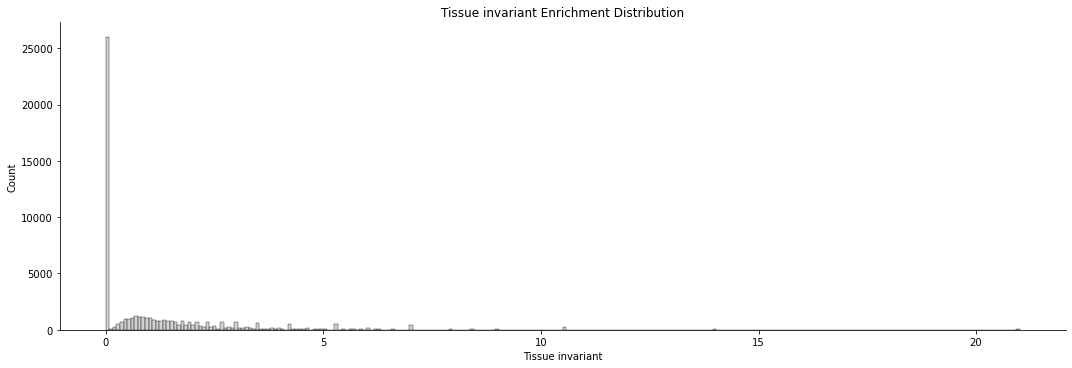

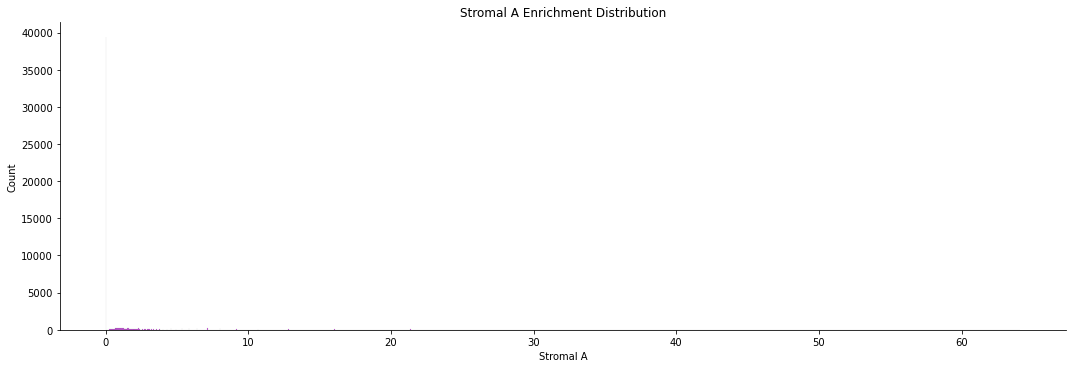

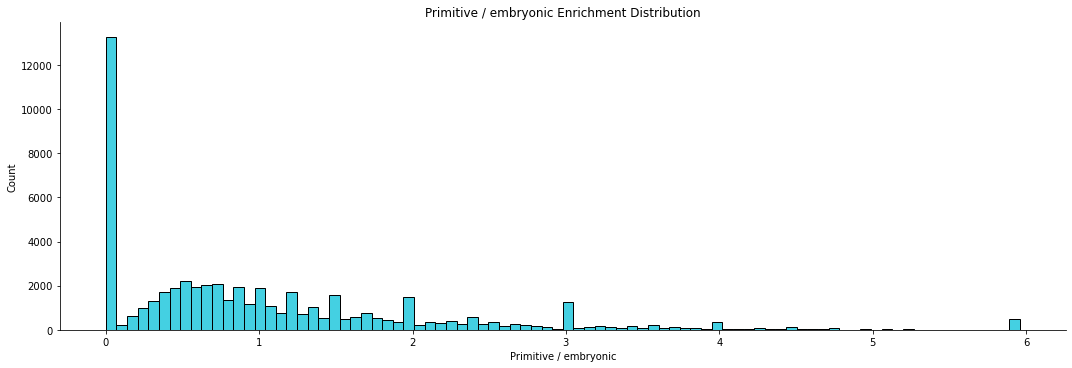

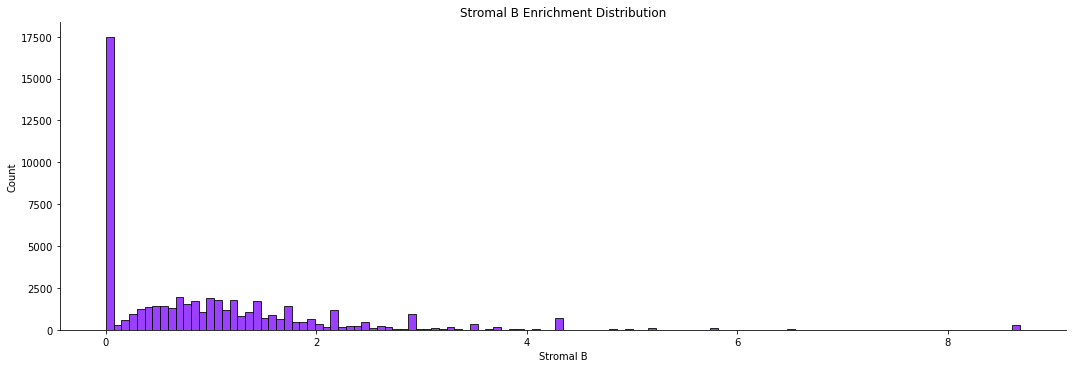

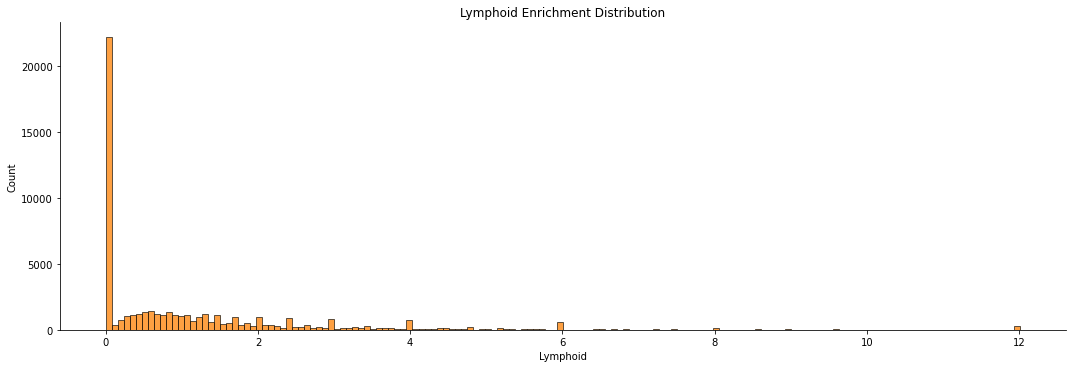

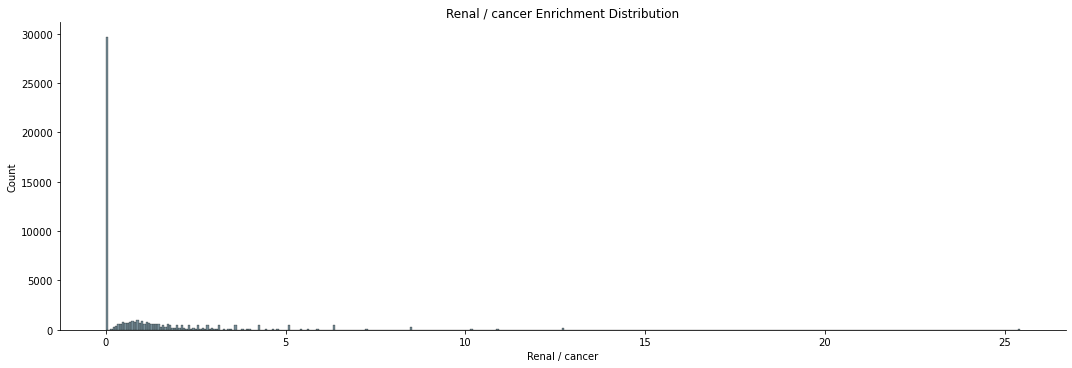

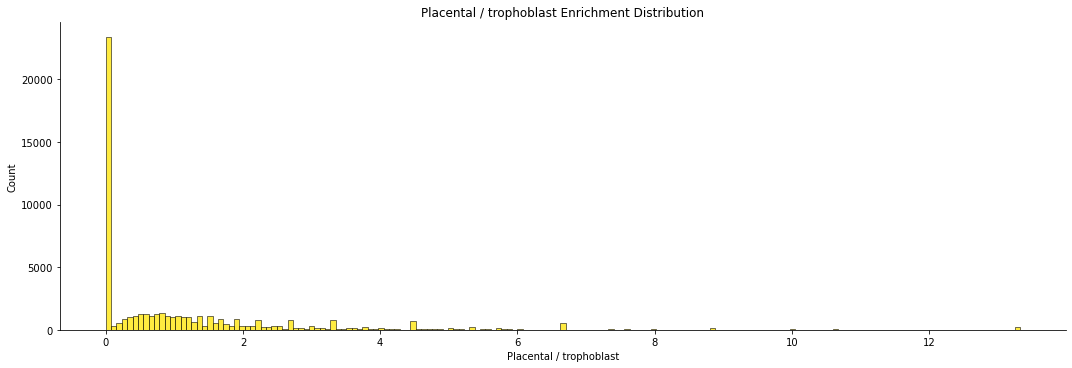

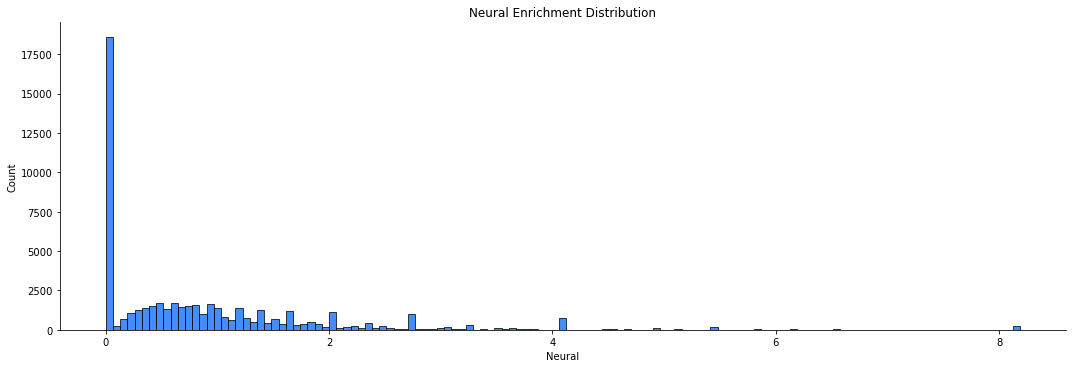

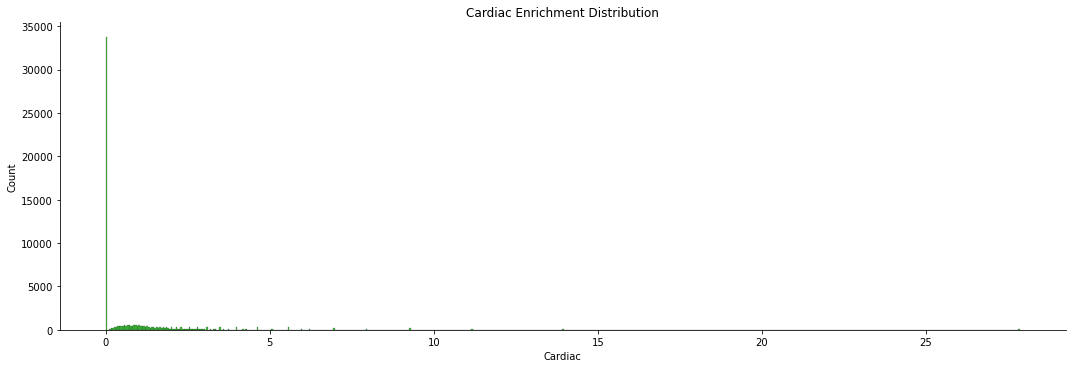

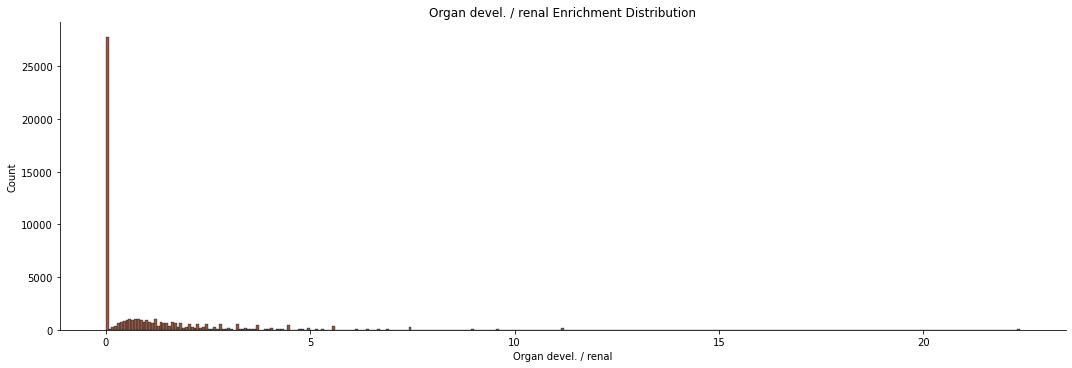

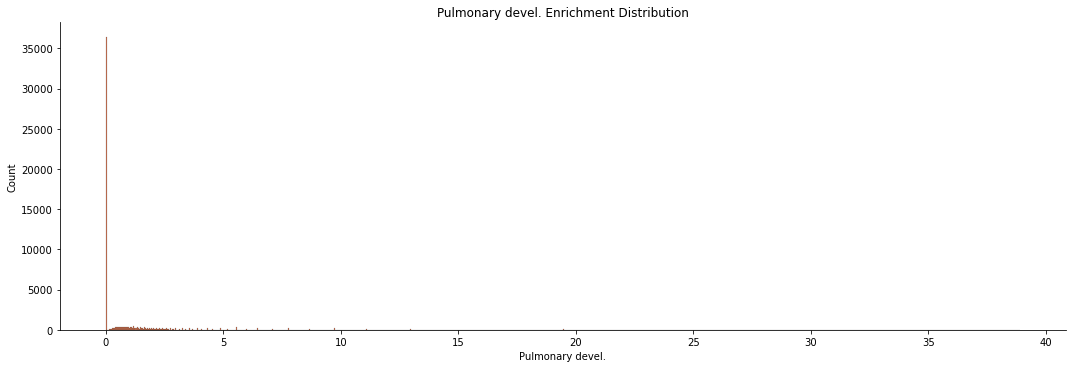

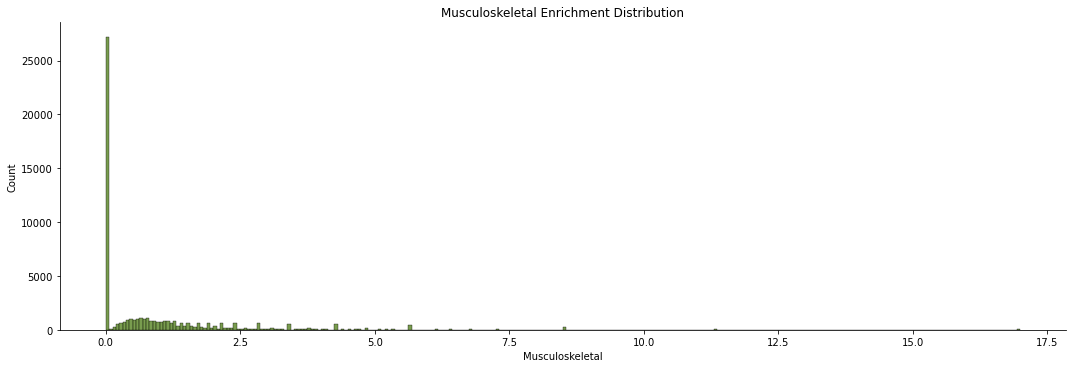

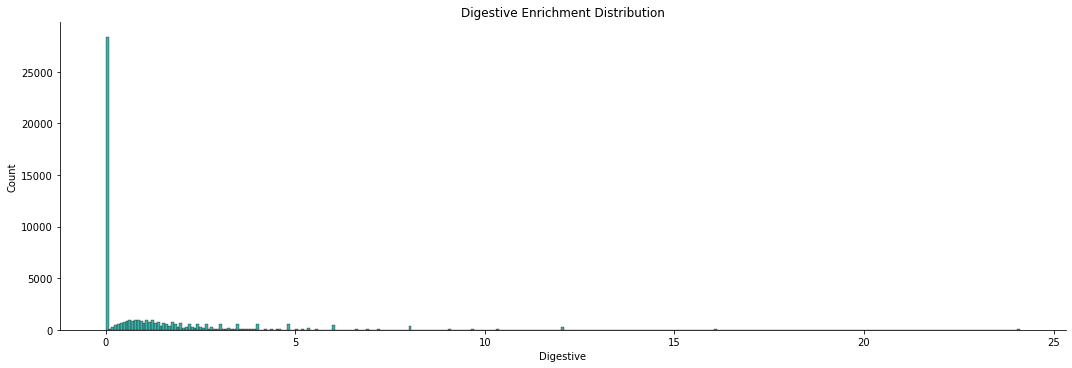

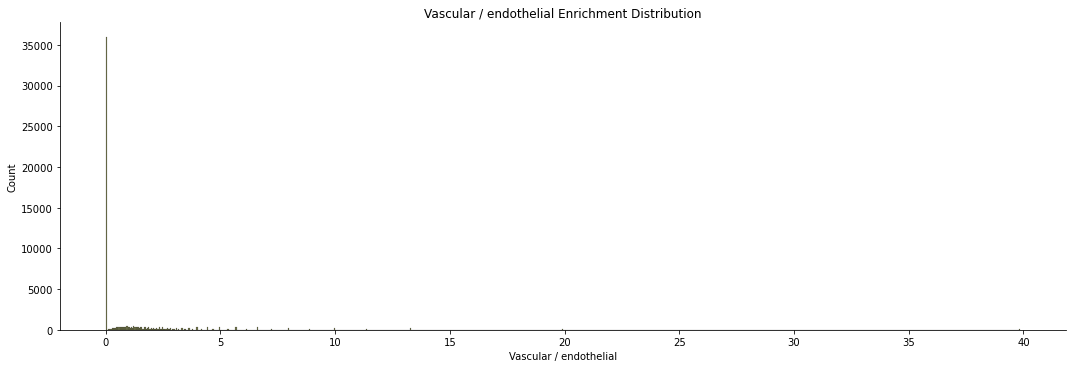

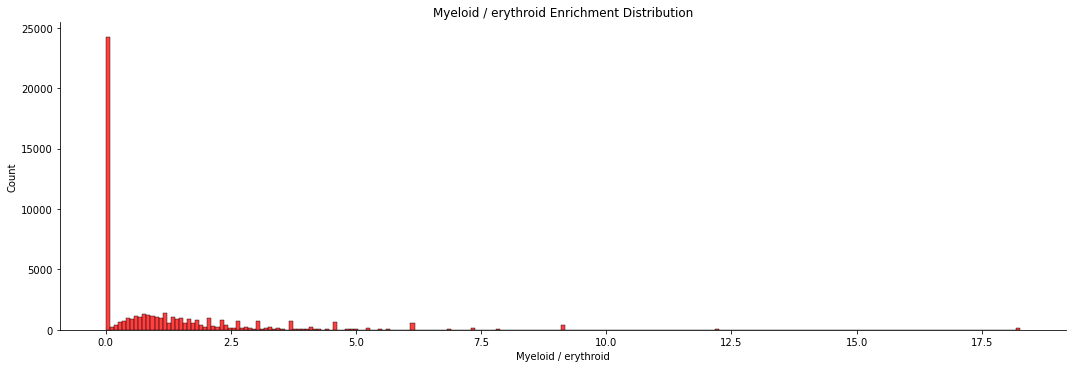

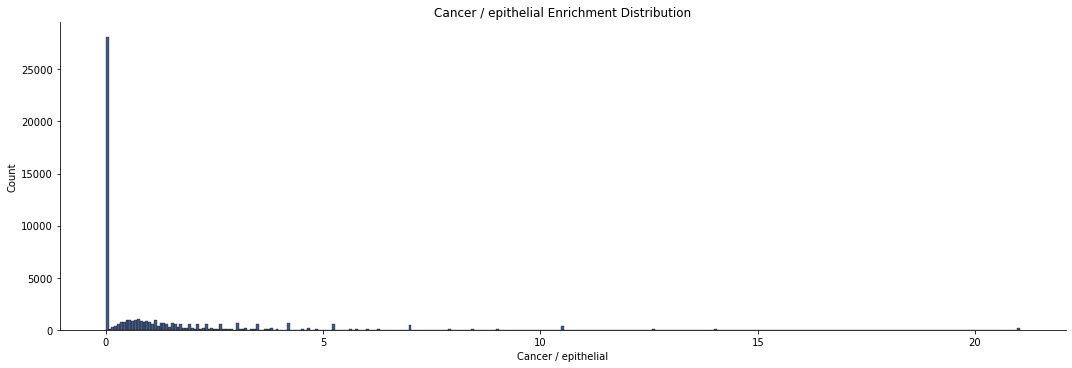

In [109]:
Comp_colors = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588',
               '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16, 10, 7, 11, 2, 12, 1, 8, 4, 15, 14, 5, 9, 6, 3, 13]).astype(int) - 1
Comp_colors = np.array(Comp_colors)[neworder]

for i, component in enumerate(official_order_vals):
    component_distr_plot = sns.displot(gene_DHS_enrichment[component], height=5, aspect=3, color = Comp_colors[i])
    component_distr_plot.set(title= component+ ' Enrichment Distribution')
    plt.show()

In [113]:
gene_DHS_enrichment.loc['GATA1']

Tissue invariant            0.807944
Stromal A                   2.464814
Primitive / embryonic       0.458440
Stromal B                   0.000000
Lymphoid                    0.000000
Renal / cancer              0.000000
Placental / trophoblast     0.512424
Neural                      0.629713
Cardiac                     0.000000
Organ devel. / renal        0.000000
Pulmonary devel.            0.000000
Musculoskeletal             0.000000
Digestive                   0.000000
Vascular / endothelial      0.000000
Myeloid / erythroid        13.346105
Cancer / epithelial         0.000000
Name: GATA1, dtype: float64

In [23]:
genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-hg38.pkl')
# print(genes_in_both)
genes_in_three = list(set(genes_in_both.preferred_name.tolist()).intersection(gene_DHS_enrichment.index.tolist()))
genes_in_three = genes_in_both[genes_in_both['preferred_name'].isin(genes_in_three)]
# print(genes_in_three)
print(gene_DHS_enrichment)
gene_DHS_enrichment = gene_DHS_enrichment.loc[genes_in_three.preferred_name].dropna(axis=0, how='all')
print(gene_DHS_enrichment)

gene_DHS_enrichment.to_pickle('../data/gene-dhs-enrichment-dropna.pkl')

# genes_in_three.to_pickle('../data/STRING-Alex-DHSenrichment-genes.pkl')

         Tissue invariant  Stromal A  Primitive / embryonic  Stromal B  \
ARF5             8.752724   0.000000               0.993287   1.447652   
M6PR             4.501401   3.051674               0.851389   0.620422   
FKBP4            0.000000   0.000000               0.595972   2.316243   
CYP26B1          0.477421   0.000000               3.115309   0.296111   
NDUFAF7          3.000934   0.000000               0.851389   1.861266   
...                   ...        ...                    ...        ...   
CERS1            0.287761   0.000000               1.551160   0.237970   
ZNF518A          4.726471   0.000000               0.446979   1.085739   
MUC5AC           0.359086   0.547736               3.412832   0.148477   
EIF3L            2.838721   0.000000               0.000000   1.643280   
OR6Q1            0.000000   0.000000               0.000000   4.342955   

         Lymphoid  Renal / cancer  Placental / trophoblast    Neural  \
ARF5     0.000000        0.000000      

In [20]:
gata1_dhs_enrichment = gene_DHS_enrichment.loc['GATA1']
# print(gata1_dhs_enrichment)

my_euclidean = functools.partial(euclidean, gata1_dhs_enrichment)
my_pearsonr = functools.partial(pearsonr, gata1_dhs_enrichment)
def percentileofscore_dhs_gene_enrichment(score):
    return percentileofscore(gata1_gene_dhsenrichment['pearson_corr'], score)

gene_DHS_enrichment[['pearson_corr', 'p-val']] = pd.DataFrame(gene_DHS_enrichment.apply(my_pearsonr, axis=1).tolist(), index=gene_DHS_enrichment.index)
gata1_gene_dhsenrichment = gene_DHS_enrichment.sort_values(by = 'pearson_corr', ascending=False)
gata1_gene_dhsenrichment['enrichment_score'] = gata1_gene_dhsenrichment['pearson_corr'].map(percentileofscore_dhs_gene_enrichment)
gata1_gene_dhsenrichment.to_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')
gata1_gene_dhsenrichment

,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial,pearson_corr,p-val,enrichment_score
GATA1,0.807944,2.464814,0.458440,0.000000,0.000000,0.000000,0.512424,0.629713,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,13.346105,0.000000,1.000000,5.574538e-111,100.000000
MBD3L5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981603,1.821924e-11,99.969040
CT45A3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981603,1.821924e-11,99.969040
CT45A10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981603,1.821924e-11,99.969040
AGAP4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.263091,0.000000,0.981603,1.821924e-11,99.969040
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AXIN2,0.963603,0.000000,0.874821,1.035934,0.991683,1.166047,1.955673,0.600827,2.300585,1.846269,1.070468,0.467630,1.327260,1.096614,0.000000,0.771784,-0.516033,4.073509e-02,0.028145
CEP112,0.762067,1.010807,0.817817,1.630321,1.022967,0.681604,0.777527,0.916758,0.966843,0.705374,1.410969,1.232754,1.825506,1.696811,0.201643,0.762959,-0.536924,3.199015e-02,0.022516
PIK3C2G,0.659201,1.072555,0.598466,1.417366,1.130685,1.595387,0.947663,0.822052,0.757771,1.216254,1.220513,1.528439,1.311525,1.000258,0.382073,1.187950,-0.564426,2.274530e-02,0.016887
PTPRM,0.710617,1.374764,0.855604,1.325820,0.336925,1.552036,0.780474,1.296834,1.609229,0.922457,1.347801,1.331768,0.994715,1.413594,0.135617,0.971735,-0.565162,2.252994e-02,0.011258


In [22]:
def percentileofscore_dhs_gene_enrichment_all(score, curr_gene):
    return percentileofscore(curr_gene, score)

pearson_scores = []

for i, gene in tqdm(enumerate(gene_DHS_enrichment.index.tolist())):
    specific_gene_dhs_enrichment = gene_DHS_enrichment.loc[gene]
    
    my_pearsonr = functools.partial(pearsonr, specific_gene_dhs_enrichment)

    gene_DHS_enrichment[['pearson_corr', 'p-val']] = pd.DataFrame(gene_DHS_enrichment.apply(my_pearsonr, axis=1).tolist(), index=gene_DHS_enrichment.index)
    pearson_scores.extend(gene_DHS_enrichment['pearson_corr'].tolist())
    

1207it [38:47,  1.93s/it]


KeyboardInterrupt: 

In [ ]:
sns.displot(pearson_scores)

In [27]:
# with open('../output/gene-dhs-distr.pkl', "rb") as input_file:
#     dhs_scores = pickle.load(input_file)

dhs_scores = np.load("../output/gene-dhs-distr.npy")
    
print(dhs_scores)

[[ 1.          0.50203783 -0.21568249 ... -0.07043285  0.30529267
   0.09546838]
 [ 0.4998962   1.         -0.27735335 ... -0.06509338 -0.01864949
  -0.04596355]
 [-0.19880556 -0.29039872  1.         ... -0.04021057 -0.1228427
   0.17083869]
 ...
 [-0.06249441 -0.04898458 -0.03752349 ...  1.         -0.24258162
  -0.17712692]
 [ 0.30401094 -0.00995816 -0.12670225 ... -0.25419835  1.
  -0.06835232]
 [ 0.09816088 -0.03895214  0.17236894 ... -0.1715516  -0.10245062
   1.        ]]


In [30]:
gene_dhs_scores = []
for i in range(len(dhs_scores)):
    gene_dhs_scores.extend(dhs_scores[i, i:])
# print(gene_dhs_scores)

IOPub data rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_data_rate_limit`.

Current values:
NotebookApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
NotebookApp.rate_limit_window=3.0 (secs)

IOStream.flush timed out


157806495


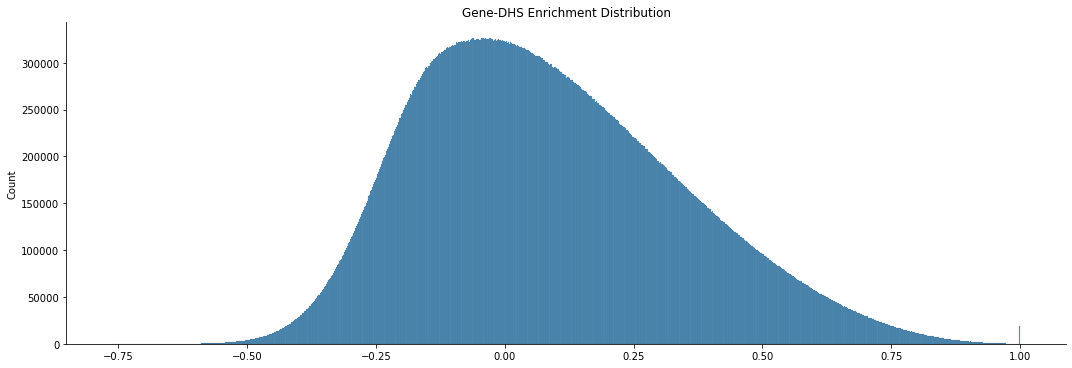

In [33]:
print(len(gene_dhs_scores))

distr_plot = sns.displot(gene_dhs_scores, height=5, aspect=3)
distr_plot.set(title='Gene-DHS Enrichment Distribution')
plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_gene-DHS-enrichment-distribution.png')


In [34]:
def percentileofscore_dhs_gene_enrichment_all(score):
    return percentileofscore(gene_dhs_scores, score)

gene_DHS_enrichment[['pearson_corr', 'p-val']] = pd.DataFrame(gene_DHS_enrichment.apply(my_pearsonr, axis=1).tolist(), index=gene_DHS_enrichment.index)
gata1_gene_dhsenrichment = gene_DHS_enrichment.sort_values(by = 'pearson_corr', ascending=False)
gata1_gene_dhsenrichment['enrichment_score'] = gata1_gene_dhsenrichment['pearson_corr'].map(percentileofscore_dhs_gene_enrichment)
gata1_gene_dhsenrichment.to_pickle('../output/GATA1-gene-dhs-enrichment_pearsonr.pkl')
gata1_gene_dhsenrichment

,Tissue invariant,Stromal A,Primitive / embryonic,Stromal B,Lymphoid,Renal / cancer,Placental / trophoblast,Neural,Cardiac,Organ devel. / renal,Pulmonary devel.,Musculoskeletal,Digestive,Vascular / endothelial,Myeloid / erythroid,Cancer / epithelial,pearson_corr,p-val,enrichment_score
IAPP,0.000000,0.000000,1.813828,0.377648,0.522191,1.105210,0.579262,1.067773,0.000000,0.000000,0.000000,0.000000,2.096686,5.196995,3.176190,0.000000,1.000000,0.000000e+00,100.000000
SLC22A25,0.000000,0.000000,0.993287,0.620422,0.285962,1.815703,0.951644,0.974555,1.326793,0.532390,0.000000,0.000000,2.296370,4.743289,3.043849,0.500741,0.942505,5.009449e-09,99.994371
CRYBA4,1.909685,0.000000,0.541793,0.000000,0.000000,2.310894,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.191990,10.866444,6.641124,0.000000,0.921083,5.892836e-08,99.988742
OR10AG1,0.000000,0.000000,1.986574,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,13.281210,6.087697,0.000000,0.907870,1.948284e-07,99.983113
CCDC179,0.000000,0.000000,2.292201,1.336294,0.000000,0.000000,0.000000,0.629713,0.000000,0.000000,0.000000,0.000000,0.000000,6.129789,4.214560,0.000000,0.905948,2.283896e-07,99.977484
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EYA1,1.269277,0.387221,1.008291,0.813484,0.253996,0.998362,1.086772,1.558110,1.346835,1.486187,1.292539,1.591261,0.437073,0.000000,0.165527,1.461377,-0.492268,3.796157e-02,0.028145
OR51E2,0.875272,2.670215,0.248322,1.085739,1.501298,1.059160,0.555126,1.023283,2.321887,0.931682,3.241140,2.831760,0.000000,0.000000,0.000000,0.876297,-0.510097,3.056035e-02,0.022516
PGRMC1,2.211214,1.686451,0.784174,1.600036,0.000000,0.668943,0.350606,1.077140,2.199682,1.765292,2.047036,1.341360,0.634523,0.000000,0.480608,0.553451,-0.515836,2.843315e-02,0.016887
MATR3,2.400747,1.831004,1.191944,1.116760,1.887346,0.726281,1.332302,0.233893,0.398038,0.958301,0.555624,0.728167,0.000000,0.000000,0.000000,2.103112,-0.526371,2.482902e-02,0.011258


# Horizontal  Barplots

In [ ]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = step2.protein2.iloc[:50]

bottom_sum = []

for i, c in enumerate(step2.columns.tolist()):
    if i == 2:
        ax.barh(labels, step2[c].iloc[:50], width, label = c, color = colors[i])
        bottom_sum = step2[c].iloc[:50]
    elif i > 2:
        ax.barh(labels, step2[c].iloc[:50], width, label = c, bottom = bottom_sum, color = colors[i])
        bottom_sum = bottom_sum + step2[c].iloc[:50]

ax.set_ylabel('Scores')
ax.set_title('Scores by Channel')
ax.legend()
# plt.show()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_step2-first50-associations.png')